<a href="https://colab.research.google.com/github/ddesiccantt/EECS498-DC/blob/main/A1_Q2_kNN_prediction_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

torch.Size([60000, 28, 28])
torch.Size([60000])
tensor([5, 0, 4, 1, 9, 2, 1, 3, 1, 4])
k=1, 验证准确率=90.80%
k=3, 验证准确率=90.80%
k=5, 验证准确率=90.60%
k=7, 验证准确率=89.60%
最佳 k=3, 验证准确率=90.8000%
torch.Size([1000])
torch.Size([1000])
预测错误的数量： 88


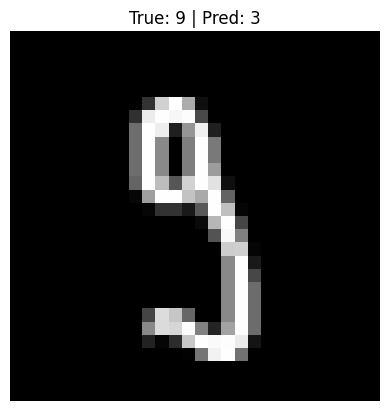

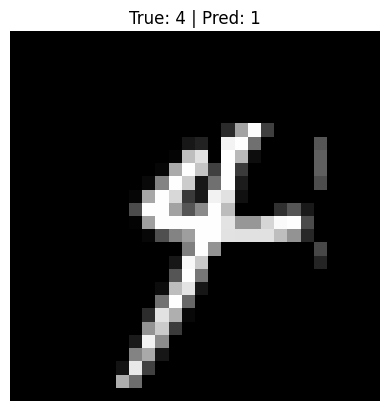

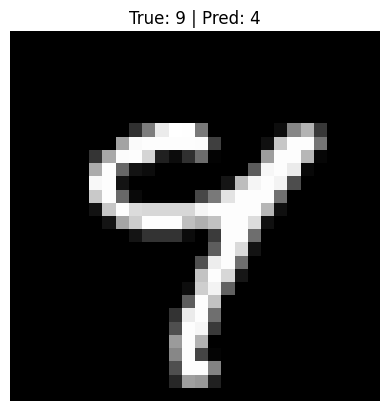

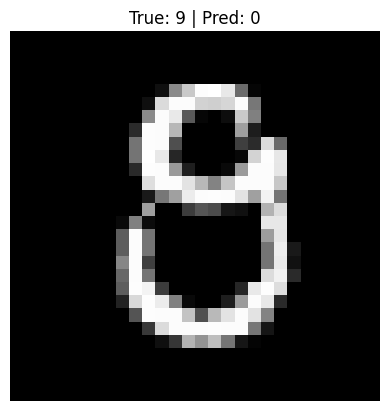

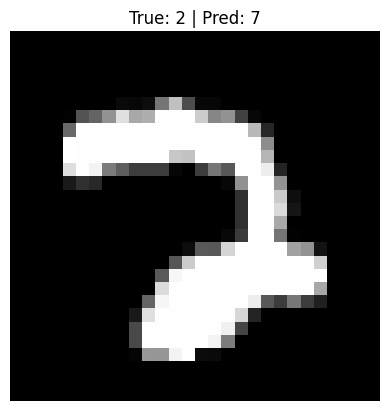

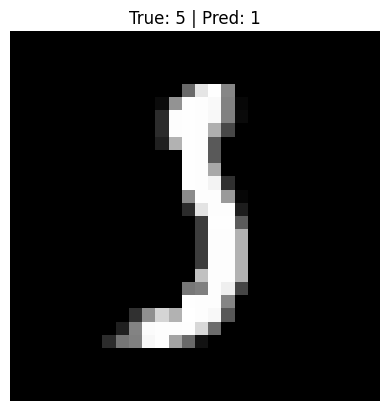

In [14]:
import torch
from torchvision.datasets import MNIST

dataset = MNIST(
    root="./data",
    train=True,
    download=True
)

images = dataset.data
labels = dataset.targets

print(images.shape)
# torch.Size([60000, 28, 28])

print(labels.shape)
# torch.Size([60000])
print(labels[:10])

import matplotlib.pyplot as plt

# plt.imshow(images[0], cmap="gray")
# plt.title(f"Label: {labels[0].item()}")
# plt.axis("off")
# plt.show()

def knn_predict_fast(train_points, train_labels, queries, k=3):
    query_squared = (queries ** 2).sum(dim=1, keepdim=True)
    train_squared = (train_points ** 2).sum(dim=1).unsqueeze(0)
    dot_products = queries @ train_points.T

    squared_distances = (
        query_squared + train_squared - 2 * dot_products
    )

    # 浮点计算可能产生极小的负数，将它们设为 0
    squared_distances = squared_distances.clamp(min=0)

    _, indices = squared_distances.topk(
        k=k, dim=1, largest=False
    )
    neighbor_labels = train_labels[indices]

    results = []
    for labels in neighbor_labels:
        prediction = torch.bincount(labels).argmax()
        results.append(prediction)

    return torch.stack(results)


def prepare_images(images):
    images_float = images.float() / 255.0
    return images_float.flatten(start_dim=1)

def knn_predict_batched(
    train_points, train_labels, queries, k=3, batch_size=100
):
    results = []

    for batch in queries.split(batch_size):
        predictions = knn_predict_fast(
            train_points, train_labels, batch, k=k
        )
        results.append(predictions)

    return torch.cat(results, dim=0)

torch.manual_seed(42)
order = torch.randperm(images.shape[0])

train_indices = order[:2000]
val_indices = order[2000:2500]

train_points = images[train_indices]
val_points = images[val_indices]

train_points = prepare_images(train_points)
val_points = prepare_images(val_points)

train_labels = labels[train_indices]
val_labels = labels[val_indices]

# print("train_points:", train_points.shape)  # 应为 [2000, 784]
# print("val_points:", val_points.shape)      # 应为 [500, 784]
# print("train_labels:", train_labels.shape)  # 应为 [2000]

# predictions = knn_predict_batch(train_points, train_labels,
#                                 val_points, k = 3, batch_size=100)
# accuracy = (predictions == val_labels).float().mean().item()

# print(f"验证准确率：{accuracy:.2%}")

best_k = None
best_accuracy = -1

for k in [1, 3, 5, 7]:
    predictions = knn_predict_batched(
        train_points, train_labels, val_points,
        k=k, batch_size=100
    )

    accuracy = (predictions == val_labels).float().mean().item()
    print(f"k={k}, 验证准确率={accuracy:.2%}")

    if accuracy >= best_accuracy:
        best_accuracy = accuracy
        best_k = k

print(f"最佳 k={best_k}, 验证准确率={best_accuracy:.4%}")
# 找出预测错误的图片索引
# wrong_indices = (predictions != train_labels).nonzero(
#     as_tuple=True
# )[0]

# print("预测错误的数量：", wrong_indices.numel())
# 同时取出前 1000 张测试图片及其标签
test_points = (
    dataset.data[:1000]
    .float()
    .flatten(start_dim=1) / 255.0
)
test_labels = dataset.targets[:1000]

# 对这 1000 张图片重新预测
test_predictions = knn_predict_batched(
    train_points, train_labels, test_points,
    k=best_k, batch_size=100
)

print(test_predictions.shape)  # [1000]
print(test_labels.shape)       # [1000]

# 找出预测错误的位置
wrong_indices = (test_predictions != test_labels).nonzero(
    as_tuple=True
)[0]

print("预测错误的数量：", wrong_indices.numel())
import matplotlib.pyplot as plt

if wrong_indices.numel() > 0:
    for index in wrong_indices[:6]:  # 前 6 张错图
        i = index.item()

        plt.figure()
        plt.imshow(dataset.data[i], cmap="gray")
        plt.title(
            f"True: {test_labels[i].item()} | "
            f"Pred: {test_predictions[i].item()}"
        )
        plt.axis("off")
        plt.show()

else:
    print("这批测试图片全部预测正确")

In [ ]:
# import torch
# pixels = torch.tensor([0, 128, 255], dtype=torch.uint8)

# pixels_float = pixels.float() / 255.0

# print(pixels_float)
# # tensor([0.0000, 0.5020, 1.0000])

# # 模拟 10 张 RGB 图片
# images = torch.randint(
#     0, 256, (10, 3, 32, 32), dtype=torch.uint8
# )

# images_float = images.float() / 255.0
# images_flat = images_float.flatten(start_dim=1)

# print(images_flat.shape)
# # torch.Size([10, 3072])

import torch

def prepare_images(images):
    images_float = images.float() / 255.0
    return images_float.flatten(start_dim=1)

images = torch.randint(
    0, 256, (20, 1, 28, 28), dtype=torch.uint8
)

flat_images = prepare_images(images)

print(flat_images.shape)
# torch.Size([20, 784])

print(flat_images.dtype)
# torch.float32

torch.Size([20, 784])
torch.float32
